## 1. Import libraries

In [12]:
import re
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Scrape book listings with BeautifulSoup

In [13]:
pd.set_option("display.max_colwidth", 100)
BASE_URL = "https://books.toscrape.com/"
HEADERS = {"User-Agent": "Mozilla/5.0 (compatible; StudentDataScienceProject/1.0)"}
rating_words = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

books = []
for page in range(1, 11):
    url = BASE_URL if page == 1 else f"{BASE_URL}catalogue/page-{page}.html"
    response = requests.get(url, headers=HEADERS, timeout=20)
    response.raise_for_status()
    soup = BeautifulSoup(response.text, "html.parser")

    for book in soup.select("article.product_pod"):
        title = book.select_one("h3 a").get("title", "").strip()
        price_text = book.select_one(".price_color").get_text(strip=True)
        price_text = price_text.replace("Â", "").replace("£", "").strip()
        rating_classes = book.select_one(".star-rating").get("class", [])
        rating_word = next((word for word in rating_words if word in rating_classes), None)
        availability = book.select_one(".availability").get_text(" ", strip=True)
        quantity_match = re.search(r"\((\d+)\s+available\)", availability, flags=re.I)

        books.append({
            "Title": title,
            "Price": price_text,
            "Rating_Word": rating_word,
            "Availability": availability,
            "Stock_Quantity": int(quantity_match.group(1)) if quantity_match else np.nan
        })
    time.sleep(0.2)  # small pause between requests

raw_df = pd.DataFrame(books)
print("Rows scraped:", len(raw_df))
display(raw_df.head())

Rows scraped: 200


,Title,Price,Rating_Word,Availability,Stock_Quantity
0,A Light in the Attic,51.77,Three,In stock,NaN
1,Tipping the Velvet,53.74,One,In stock,NaN
2,Soumission,50.10,One,In stock,NaN
3,Sharp Objects,47.82,Four,In stock,NaN
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock,NaN


### What this step does
- `requests.get()` downloads the page.
- `BeautifulSoup(..., "html.parser")` reads the HTML.
- `article.product_pod` selects each book card.
- The regular expression extracts a quantity only when a quantity is explicitly displayed.
- `raise_for_status()` makes HTTP errors visible rather than silently continuing.

## 3. Clean and prepare the data

In [14]:
df = raw_df.copy()
df["Title"] = df["Title"].astype("string").str.strip()
df["Price"] = pd.to_numeric(
    df["Price"].astype("string").str.replace("£", "", regex=False).str.replace("Â", "", regex=False),
    errors="coerce"
)
df["Rating"] = df["Rating_Word"].map(rating_words)
df["Availability"] = df["Availability"].astype("string").str.strip()
df["Stock_Status"] = df["Availability"].str.strip().str.startswith("In stock", na=False)
df["Stock_Status"] = df["Stock_Status"].map({True: "In stock",False: "Out of stock"})
df["Stock_Quantity"] = pd.to_numeric(df["Stock_Quantity"], errors="coerce")

rows_before = len(df)
df = df.drop_duplicates(subset=["Title"]).dropna(subset=["Title", "Price", "Rating"]).reset_index(drop=True)
print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", len(df))
print("\nMissing values:")
display(df.isna().sum().to_frame("Missing count"))
display(df.head())

Rows before cleaning: 200
Rows after cleaning: 200

Missing values:


,Missing count
Title,0
Price,0
Rating_Word,0
Availability,0
Stock_Quantity,200
Rating,0
Stock_Status,0


,Title,Price,Rating_Word,Availability,Stock_Quantity,Rating,Stock_Status
0,A Light in the Attic,51.77,Three,In stock,NaN,3,In stock
1,Tipping the Velvet,53.74,One,In stock,NaN,1,In stock
2,Soumission,50.1,One,In stock,NaN,1,In stock
3,Sharp Objects,47.82,Four,In stock,NaN,4,In stock
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock,NaN,5,In stock


## 4. Save the final dataset

In [4]:
df = df[[
    "Title",
    "Price",
    "Rating",
    "Rating_Word",
    "Availability",
    "Stock_Status",
    "Stock_Quantity"
]]

df.to_csv("books_dataset.csv", index=False)

print("Saved books_dataset.csv")

Saved books_dataset.csv


## 5. Explore the dataset

In [5]:
print("Dataset shape:", df.shape)
print("\nSummary statistics:")
display(df[["Price", "Rating"]].describe())
print("\nRating counts:")
display(df["Rating"].value_counts().sort_index().rename("Number of books").to_frame())
print("\nAvailability counts:")
display(df["Availability"].value_counts().to_frame("Number of books"))

Dataset shape: (200, 7)

Summary statistics:


,Price,Rating
count,200.0,200.000000
mean,34.79625,2.865000
std,14.119272,1.451658
min,10.16,1.000000
25%,21.99,2.000000
50%,35.64,3.000000
75%,46.11,4.000000
max,59.64,5.000000



Rating counts:


,Number of books
Rating,
1,49
2,41
3,35
4,38
5,37



Availability counts:


,Number of books
Availability,
In stock,200


## 6. Visualisations and interpretation

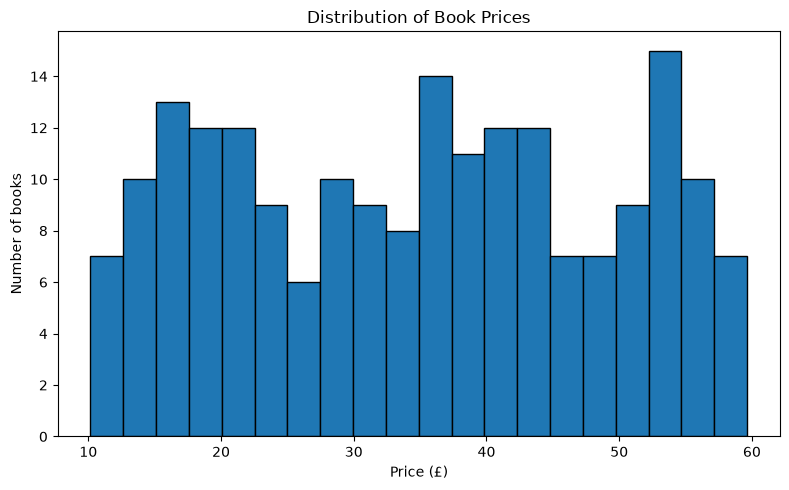

In [6]:
plt.figure(figsize=(8, 5))
plt.hist(df["Price"], bins=20, edgecolor="black")
plt.xlabel("Price (£)")
plt.ylabel("Number of books")
plt.title("Distribution of Book Prices")
plt.tight_layout()
plt.show()

### Interpretation of Book Price Distribution

The book prices range from £10.16 to £59.64. The average price is £34.80,
while the median price is £35.64. This indicates that the typical book in this sample costs approximately £35.
The histogram helps show how prices are distributed across the catalogue and whether books are concentrated in particular price ranges.
These results describe the 200 books collected and may not represent the entire catalogue.

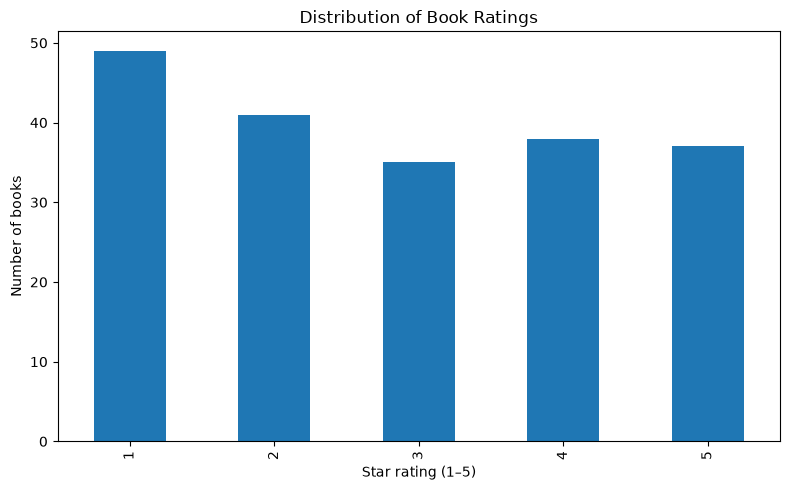

In [7]:
plt.figure(figsize=(8, 5))
df["Rating"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Star rating (1–5)")
plt.ylabel("Number of books")
plt.title("Distribution of Book Ratings")
plt.tight_layout()
plt.show()

### Interpretation of Book Ratings

The dataset contains 49 one-star books, 41 two-star books, 35 three-star books,
38 four-star books and 37 five-star books. One-star books are the most common rating category,
while three-star books are the least common. However, the counts are relatively similar across the rating categories,
indicating that the sample contains a range of ratings.

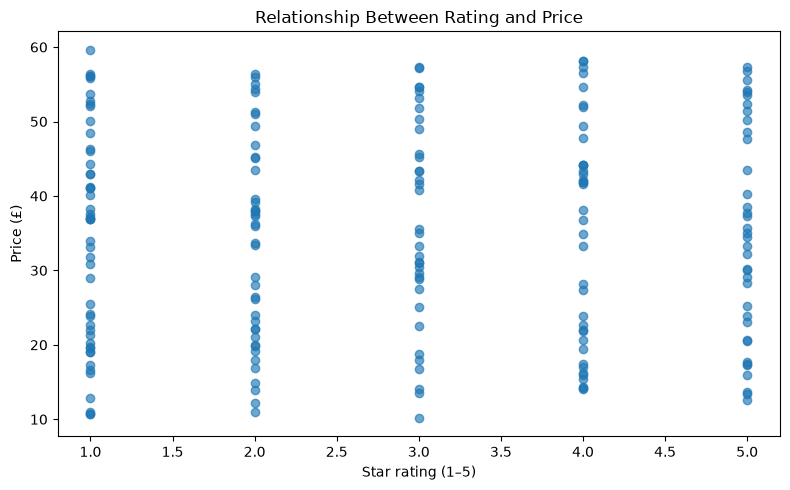

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Rating"], df["Price"], alpha=0.65)
plt.xlabel("Star rating (1–5)")
plt.ylabel("Price (£)")
plt.title("Relationship Between Rating and Price")
plt.tight_layout()
plt.show()

### Interpretation of Rating and Price

The scatter plot shows that book prices vary considerably at different star
ratings. The correlation between rating and price is approximately 0.017,
which indicates almost no linear relationship in this sample. Therefore, star
rating alone does not appear to be a useful indicator of book price.
Other factors, such as genre and book characteristics, could be investigated in future analysis.

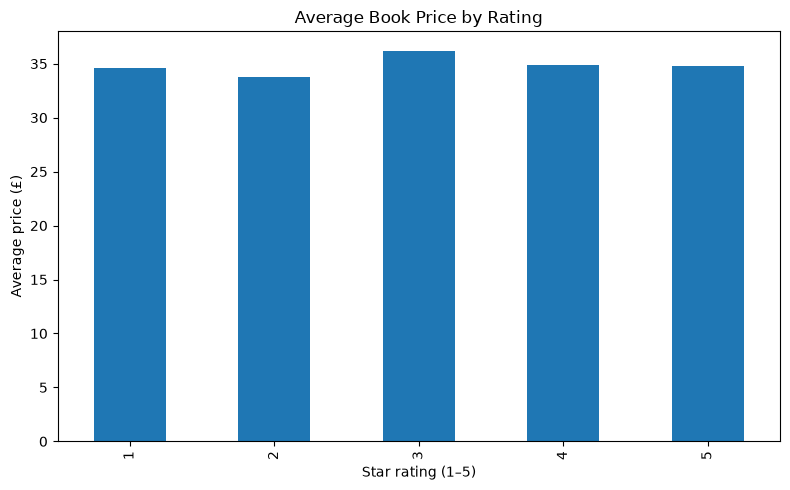

,Average price (£)
Rating,
1,34.585102
2,33.739756
3,36.191143
4,34.896579
5,34.824054


In [9]:
average_price = df.groupby("Rating")["Price"].mean()
average_price.plot(kind="bar", figsize=(8, 5))
plt.xlabel("Star rating (1–5)")
plt.ylabel("Average price (£)")
plt.title("Average Book Price by Rating")
plt.tight_layout()
plt.show()
display(average_price.to_frame("Average price (£)"))

###Intertation of Average Price by Rating

The average prices for one-star, two-star, three-star, four-star and five-star books
are approximately £34.59, £33.74, £36.19, £34.90 and £34.82,
respectively. Three-star books have the highest average price, while two-star
books have the lowest. The differences are relatively small, which
supports the finding that star rating does not have a strong relationship
with price in this sample. These averages do not establish that a book's 
rating causes its price to change.

## 7. Predictive modelling: linear regression

In [10]:
model_df = df.dropna(subset=["Title", "Price", "Rating"]).copy()
X = model_df[["Title", "Rating"]]
y = model_df["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("title_text", TfidfVectorizer(max_features=250, ngram_range=(1, 2)), "Title"),
        ("rating", StandardScaler(), ["Rating"])
    ]
)
model = Pipeline([
    ("features", preprocessor),
    ("regression", LinearRegression())
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Training rows: {len(X_train)}")
print(f"Test rows: {len(X_test)}")
print(f"MAE (£): {mae:.2f}")
print(f"MSE (£²): {mse:.2f}")
print(f"RMSE (£): {rmse:.2f}")
print(f"R-squared: {r2:.3f}")


baseline_pred = np.full(len(y_test), y_train.mean())

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

print("\nMean-price baseline:")
print(f"Baseline MAE (£): {baseline_mae:.2f}")
print(f"Baseline RMSE (£): {baseline_rmse:.2f}")
print(f"Baseline R-squared: {baseline_r2:.3f}")

print("\nModel comparison:")
print(f"Linear regression MAE (£): {mae:.2f}")
print(f"Linear regression RMSE (£): {rmse:.2f}")
print(f"Linear regression R-squared: {r2:.3f}")




Training rows: 160
Test rows: 40
MAE (£): 18.84
MSE (£²): 537.07
RMSE (£): 23.17
R-squared: -1.327

Mean-price baseline:
Baseline MAE (£): 13.40
Baseline RMSE (£): 15.24
Baseline R-squared: -0.007

Model comparison:
Linear regression MAE (£): 18.84
Linear regression RMSE (£): 23.17
Linear regression R-squared: -1.327


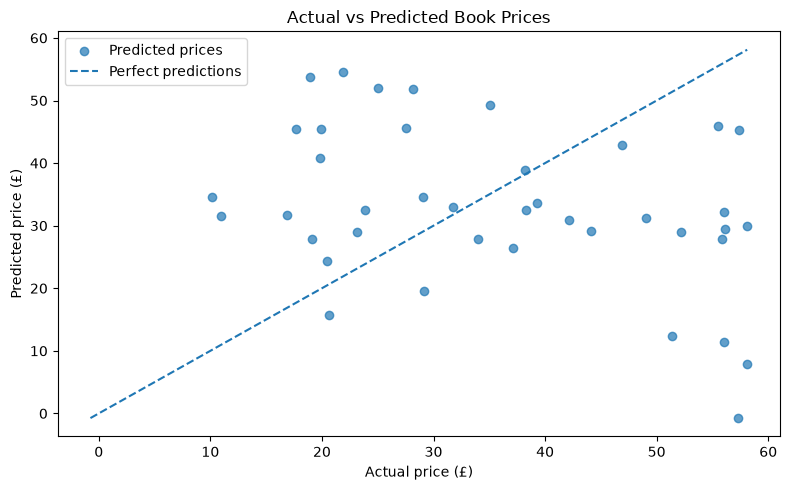

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.7, label="Predicted prices")

min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    label="Perfect predictions"
)

plt.xlabel("Actual price (£)")
plt.ylabel("Predicted price (£)")
plt.title("Actual vs Predicted Book Prices")
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation of Predictive Model Results

The linear regression model achieved a Mean Absolute Error (MAE) of £18.84 and a Root Mean Squared Error (RMSE) of £23.17.
These errors indicate that the model's price predictions are not sufficiently accurate for reliable pricing decisions.
The R-squared value of -1.327 shows that the model performed worse than a baseline that predicts the mean price of the test set.
One possible reason is that the selected features, book title and star rating, do not provide enough useful information to predict prices for unseen books.
Future work could investigate additional features, such as genre or category, and compare the model against a simple mean-price baseline.

- **MAE:** the average absolute difference between predicted and actual prices, in pounds. Smaller is better.
- **MSE:** the average squared prediction error; larger errors receive a stronger penalty.
- **RMSE:** the square root of MSE, expressed in pounds. Smaller is better.
- **R-squared:** compares the model with a baseline that predicts the test-set mean. A value near 0 indicates little improvement; a negative value means this model performed worse than that baseline on this test split.